<a href="https://colab.research.google.com/github/sakshishetty841/benchmark-_lab/blob/main/benchmark_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

NumPy version: 2.1.3


In [ ]:
N = 1_000_000


base = np.arange(N, dtype=np.int64) % 10 + 1

dtypes = [
    np.int8, np.int16, np.int32, np.int64,
    np.float16, np.float32, np.float64
]

arrays = {
    np.dtype(dtype).name: base.astype(dtype)
    for dtype in dtypes
}

print("Arrays created successfully!")

for name, arr in arrays.items():
    print(name, "Shape:", arr.shape, "Dtype:", arr.dtype)

Arrays created successfully!
int8 Shape: (1000000,) Dtype: int8
int16 Shape: (1000000,) Dtype: int16
int32 Shape: (1000000,) Dtype: int32
int64 Shape: (1000000,) Dtype: int64
float16 Shape: (1000000,) Dtype: float16
float32 Shape: (1000000,) Dtype: float32
float64 Shape: (1000000,) Dtype: float64


In [ ]:
memory_data = []

for name, arr in arrays.items():
    memory_data.append({
        "Data Type": name,
        "Number of Elements": arr.size,
        "Item Size (bytes)": arr.itemsize,
        "Total Memory (bytes)": arr.nbytes,
        "Memory (MB)": round(arr.nbytes / (1024 ** 2), 2)
    })

memory_df = pd.DataFrame(memory_data)
display(memory_df)

,Data Type,Number of Elements,Item Size (bytes),Total Memory (bytes),Memory (MB)
0,int8,1000000,1,1000000,0.95
1,int16,1000000,2,2000000,1.91
2,int32,1000000,4,4000000,3.81
3,int64,1000000,8,8000000,7.63
4,float16,1000000,2,2000000,1.91
5,float32,1000000,4,4000000,3.81
6,float64,1000000,8,8000000,7.63


In [ ]:
benchmark_data = []
REPEATS = 10

for name, arr in arrays.items():

    start = time.perf_counter()

    for _ in range(REPEATS):
        result_sum = np.sum(arr)

    sum_time = (time.perf_counter() - start) / REPEATS


    start = time.perf_counter()

    for _ in range(REPEATS):
        result_mul = arr * 2

    mul_time = (time.perf_counter() - start) / REPEATS

    benchmark_data.append({
        "Data Type": name,
        "Sum Time (ms)": round(sum_time * 1000, 3),
        "Multiply Time (ms)": round(mul_time * 1000, 3)
    })

benchmark_df = pd.DataFrame(benchmark_data)
display(benchmark_df)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


,Data Type,Sum Time (ms),Multiply Time (ms)
0,int8,0.674,0.235
1,int16,0.436,0.214
2,int32,0.616,0.528
3,int64,0.407,0.763
4,float16,2.311,6.300
5,float32,0.241,0.231
6,float64,0.301,0.669


In [ ]:

value = np.array([200], dtype=np.int64)

converted = value.astype(np.int8)

print("Original value:", value[0])
print("After conversion to int8:", converted[0])

Original value: 200
After conversion to int8: -56


In [ ]:

value = np.array([16777217], dtype=np.int64)

float16_value = value.astype(np.float16)
float32_value = value.astype(np.float32)
float64_value = value.astype(np.float64)

print("Original integer:", value[0])
print("As float16:", float16_value[0])
print("As float32:", float32_value[0])
print("As float64:", float64_value[0])

Original integer: 16777217
As float16: inf
As float32: 16777216.0
As float64: 16777217.0


/tmp/ipykernel_763/239632241.py:4: RuntimeWarning: overflow encountered in cast
  float16_value = value.astype(np.float16)


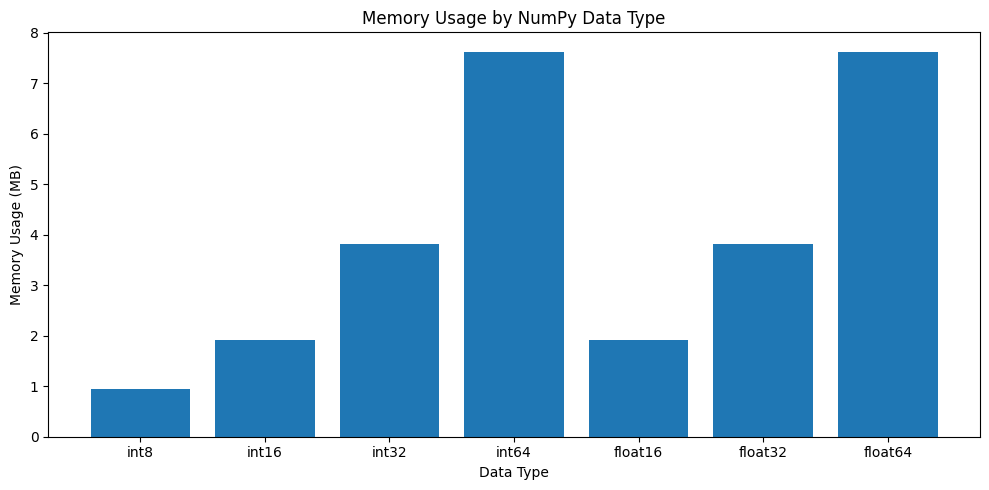

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(memory_df["Data Type"], memory_df["Memory (MB)"])

plt.title("Memory Usage by NumPy Data Type")
plt.xlabel("Data Type")
plt.ylabel("Memory Usage (MB)")
plt.tight_layout()
plt.show()

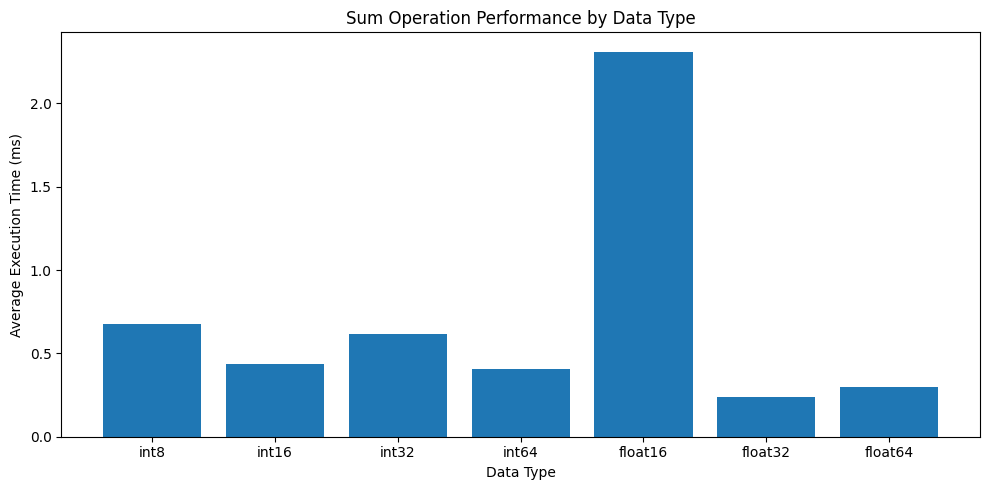

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    benchmark_df["Data Type"],
    benchmark_df["Sum Time (ms)"]
)

plt.title("Sum Operation Performance by Data Type")
plt.xlabel("Data Type")
plt.ylabel("Average Execution Time (ms)")
plt.tight_layout()
plt.show()

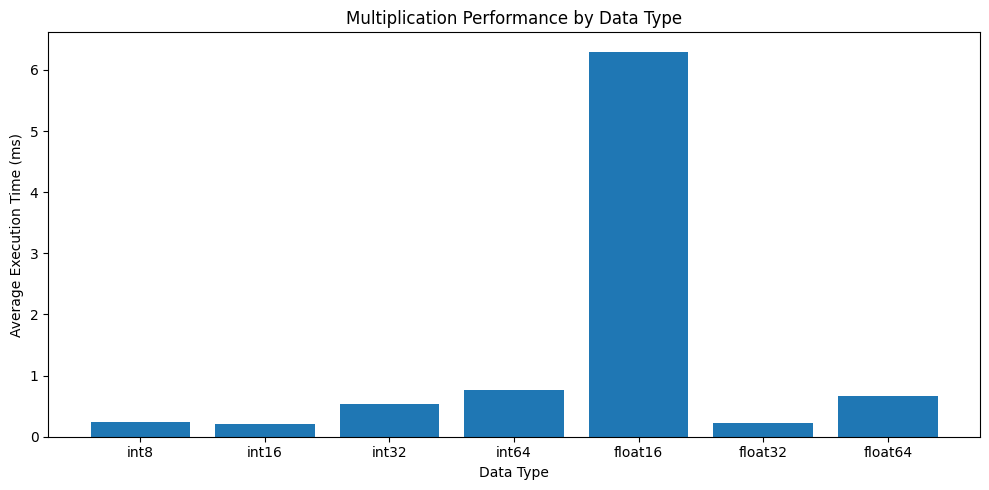

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    benchmark_df["Data Type"],
    benchmark_df["Multiply Time (ms)"]
)

plt.title("Multiplication Performance by Data Type")
plt.xlabel("Data Type")
plt.ylabel("Average Execution Time (ms)")
plt.tight_layout()
plt.show()

In [ ]:
comparison_df = memory_df.merge(benchmark_df, on="Data Type")
display(comparison_df)

print("\nRECOMMENDATIONS")
print("1. int8 uses the least memory for small whole numbers.")
print("2. int16 and int32 are suitable when larger integer ranges are needed.")
print("3. int64 is useful for large integers and avoids many overflow problems.")
print("4. float16 saves memory but has lower numerical precision.")
print("5. float32 is useful for many machine learning tasks.")
print("6. float64 is preferred when higher floating-point precision is required.")
print("7. Always benchmark performance and verify numerical accuracy.")

,Data Type,Number of Elements,Item Size (bytes),Total Memory (bytes),Memory (MB),Sum Time (ms),Multiply Time (ms)
0,int8,1000000,1,1000000,0.95,0.674,0.235
1,int16,1000000,2,2000000,1.91,0.436,0.214
2,int32,1000000,4,4000000,3.81,0.616,0.528
3,int64,1000000,8,8000000,7.63,0.407,0.763
4,float16,1000000,2,2000000,1.91,2.311,6.300
5,float32,1000000,4,4000000,3.81,0.241,0.231
6,float64,1000000,8,8000000,7.63,0.301,0.669



RECOMMENDATIONS
1. int8 uses the least memory for small whole numbers.
2. int16 and int32 are suitable when larger integer ranges are needed.
3. int64 is useful for large integers and avoids many overflow problems.
4. float16 saves memory but has lower numerical precision.
5. float32 is useful for many machine learning tasks.
6. float64 is preferred when higher floating-point precision is required.
7. Always benchmark performance and verify numerical accuracy.
